In [16]:
import matplotlib.pyplot as plt
import math
import pandas as pd
from pandas import DataFrame

In [17]:
DATA = pd.read_csv('iterations.csv')
df = DATA[['ngen','fitness','parameters']] 
#df = data[data['fitness'] < 0.81]
print(df.shape)

(6056, 3)


In [18]:
from mass_action import MAPFactory, MAParameters, MassAction, plot_trajectory
import ast

FACTORY = MAPFactory()

ea_trajectories = []
trajectory = []
num = 0 
for index, row in df.iterrows():
    #print(index)
    fitness = (row['fitness'])
    ngen = (row['ngen'])
    if ngen == 1:
        if trajectory:
            ea_trajectories.append(trajectory)
        trajectory = []
    trajectory.append((ngen,fitness))

    """
    l = ast.literal_eval(row['parameters'])
    p = FACTORY.from_list(l)
    model = MassAction(p)
    plot_trajectory(model)
    """
  

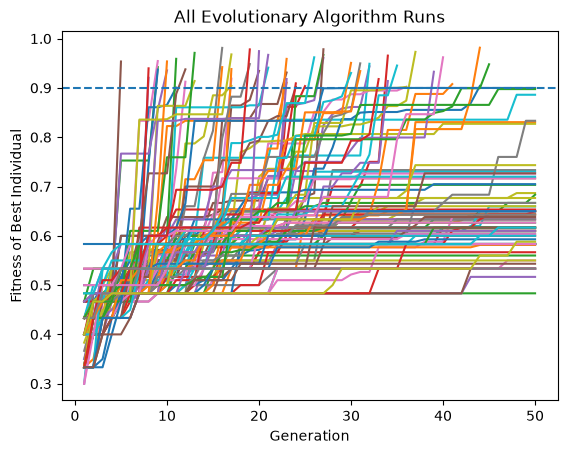

In [19]:
for trajectory in ea_trajectories:
    x, y = zip(*trajectory)
    plt.plot(x,y)
    plt.title("All Evolutionary Algorithm Runs")
    plt.xlabel("Generation")
    plt.ylabel("Fitness of Best Individual")
plt.axhline(y=0.9,linestyle="--")


plt.savefig("figures/all_trajectories.png")
plt.show()

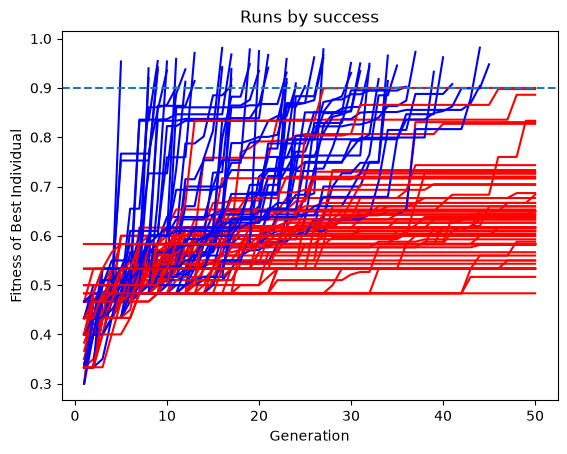

In [20]:
for trajectory in ea_trajectories:
    if trajectory[-1][1] > 0.9:
        color = 'blue'
    else:
        color = 'red'
    plt.title("Runs by success")
    plt.xlabel("Generation")
    plt.ylabel("Fitness of Best Individual")
    x, y = zip(*trajectory)
    plt.plot(x,y, color=color)
plt.axhline(y=0.9,linestyle="--")

plt.savefig("figures/colored_trajectories.png")
plt.show()

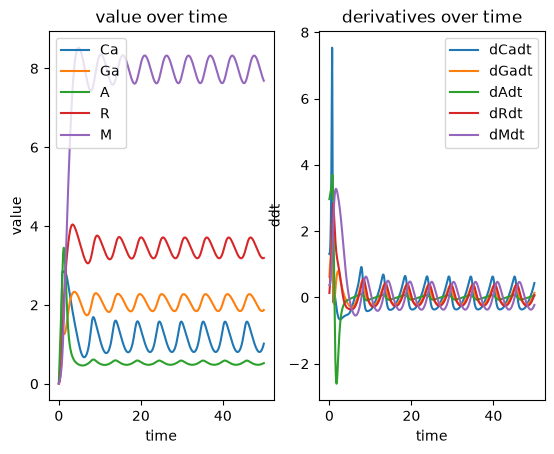

In [21]:
def plot_by_index(i, file=None):
    row = DATA.iloc[i]
    l = ast.literal_eval(row['parameters'])
    p = FACTORY.from_list(l)
    model = MassAction(p)
    plot_trajectory(model,save_file=file)

plot_by_index(3200)

In [22]:
df_osc = df[df['fitness'] > 0.90]
"""
for i, row in df_osc.iterrows():
    plot_by_index(i,file=f'figures/osc/{i}.png')
"""

"\nfor i, row in df_osc.iterrows():\n    plot_by_index(i,file=f'figures/osc/{i}.png')\n"

(6056, 23)
(1245, 23)


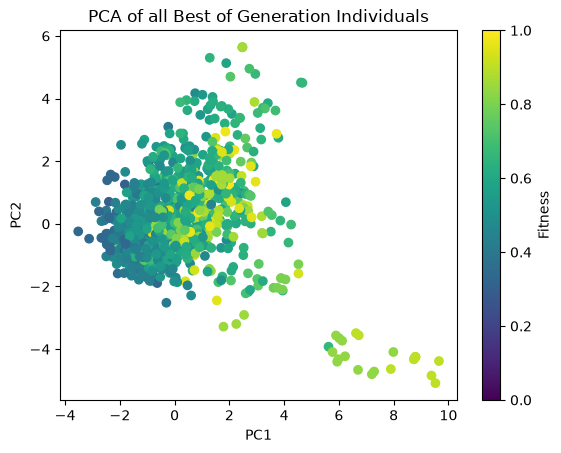

In [23]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# X: DataFrame containing the features for PCA
# df['additional_feature']: values between 0 and 1
Xy = DataFrame(columns=list(range(23)))
for i, row in DATA.iterrows():
    features = ast.literal_eval(row['parameters'])
    fitness = row['fitness']
    Xy.loc[len(Xy)] = features + [fitness]

print(Xy.shape)
Xy = Xy.drop_duplicates()
print(Xy.shape)
X = Xy[range(22)]
y = Xy[[22]]

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots()

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    vmin=0,
    vmax=1
)

fig.colorbar(sc, ax=ax, label='Fitness')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.title('PCA of all Best of Generation Individuals')

plt.savefig('figures/pca.png')
plt.show()

In [24]:
Xy.iloc[0]

0     1.611658
1     1.111658
2     2.521402
3     0.110930
4     0.241958
5     0.550640
6     1.588749
7     0.855725
8     1.422999
9     0.531327
10    1.148497
11    0.378328
12    4.060129
13    0.155023
14    3.335166
15    0.483117
16    0.090256
17    0.154897
18    0.943690
19    0.195681
20    2.271432
21    0.484139
22    0.333333
Name: 0, dtype: float64

In [25]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2']
)
loadings

,PC1,PC2
0,0.139535,-0.099102
1,0.382093,-0.287689
2,-0.047854,0.188656
3,0.375179,-0.122258
4,0.041541,0.267762
5,0.169485,0.304184
6,0.215329,0.021429
7,0.027444,0.296699
8,0.447093,-0.113229
9,0.186788,0.152974


In [26]:
from sklearn.linear_model import LinearRegression
import numpy as np

for i, row in X.T.iterrows():
    model = LinearRegression()
    a = np.array(row).reshape(-1,1)
    print(i)
    model.fit(a, np.array(y))
    score = model.score(a,np.array(y))
    print(score)
    plt.scatter(a, y)
    plt.savefig(f'figures/regression/{i}.png')
    plt.clf()
    
#Conclusion: poor correlation between fitness and individual parameters

0
0.017225764140058608
1
0.06489848856500002
2
0.04120027447517716
3
0.2570477100716707
4
8.002876636803435e-05
5
0.15959312168111028
6
0.18031968072474414
7
0.028719409402542917
8
0.1210809828708268
9
0.009166738815955977
10
0.012156764499393291
11
0.09697914146486619
12
0.003567665351209448
13
0.021684861469225103
14
0.016282081757476252
15
0.03251320223191645
16
0.11737006997390365
17
0.00029925736232550015
18
0.02423402331218949
19
0.011488703111394605
20
0.026965241262618456
21
0.09998690144884759


<Figure size 640x480 with 0 Axes>

In [27]:
#TODO Distribution of optimal parameters
#boxplots where each box is a 
# For osc

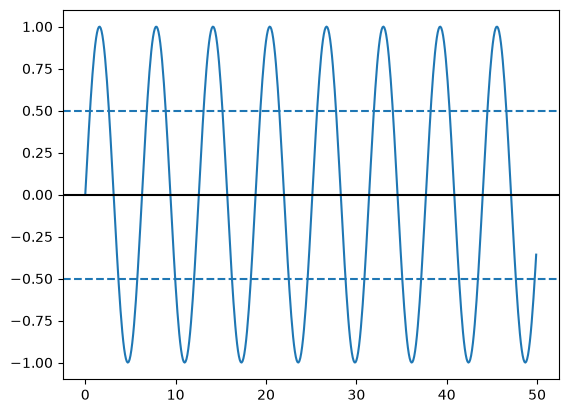

In [28]:
#Sup Figure
t = [x/10 for x in range(500)]
plt.plot(t, np.sin(t))
plt.axhline(y=0, linestyle='-', color='black')
plt.axhline(y=0.5, linestyle='--')
plt.axhline(y=-0.5, linestyle='--')

plt.savefig('figures/objective_function.png')
plt.show()

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R²:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

/usr/lib/python3.14/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


R²: 0.7559657237103279
MSE: 0.005365847220160224


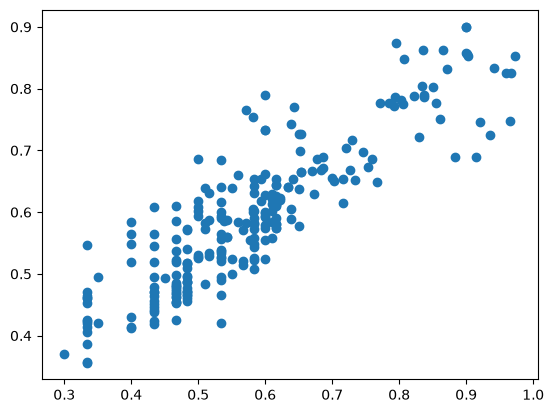

In [32]:
plt.scatter(y_test, y_pred)
plt.show()

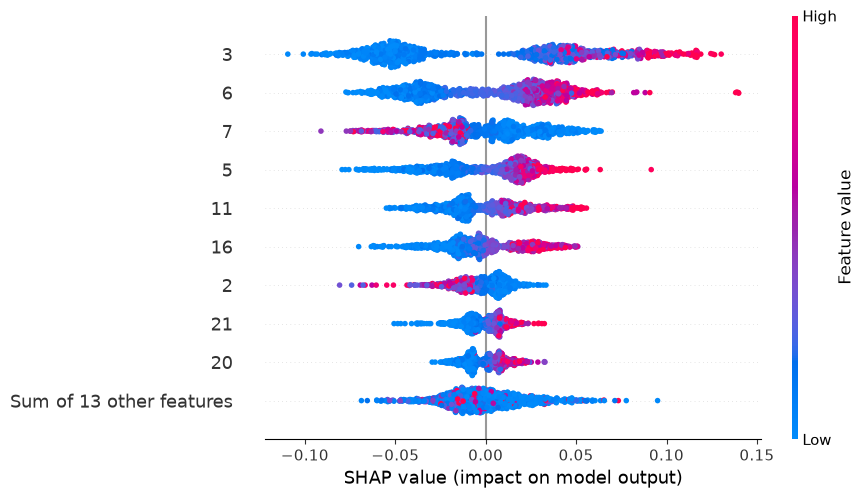

<Figure size 640x480 with 0 Axes>

In [30]:
#SHAP Plot
import shap


explainer = shap.TreeExplainer(model)
shap_values = explainer(X)

shap.plots.beeswarm(shap_values)
plt.savefig('figures/shap.png')
plt.show()